# Transformer: Language Modeling

Train a three-block, width-128 causal transformer on Tiny Shakespeare, a 1,115,394-character corpus distributed with Karpathy’s char-rnn examples. Contiguous 80/10/10 text ranges define train/validation/test. Windows do not cross split boundaries.

Source: [Tiny Shakespeare](https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare). The underlying Shakespeare texts are public domain. This run uses the file SHA-256 recorded in the experiment metadata.

The outputs below are saved from local GPU training. Documentation builds render these saved outputs without running cells.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd() if (Path.cwd() / 'examples').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import jax
import numpy as np
import pandas as pd
import jaxsaw as js
from jaxsaw import models, training
from IPython.display import display, Image, Code
RUN = ROOT / 'runs' / 'gallery/transformer'
print(f"JAXsaw {js.__version__} · JAX {jax.__version__}")
print(jax.devices())

JAXsaw 0.1.0 · JAX 0.5.3


[CudaDevice(id=0)]


## Architecture

Context length 128; fixed 128-symbol ASCII vocabulary; output `[B,T,128]`. Targets are shifted by one character. Attention uses boolean allowed-position masks. Training uses cross-entropy and a learning rate of 0.0003.

The definition below is the actual package implementation used by this run.

In [2]:
display(Code(inspect.getsource(models.TinyLanguageModel), language="python"))

class TinyLanguageModel(nn.Module):
    def __init__(self, vocab_size, max_length, width=32, depth=2, heads=4, *, rngs):
        super().__init__()
        self.max_length = max_length
        self.token = nn.Embedding(vocab_size, width, rngs=rngs)
        self.position = nn.Embedding(max_length, width, rngs=rngs)
        self.blocks = nn.ModuleList(
            [TransformerBlock(width, heads, rngs=rngs) for _ in range(depth)]
        )
        self.norm = nn.LayerNorm(width)
        self.head = nn.Linear(width, vocab_size, rngs=rngs)

    def forward(self, tokens, *, valid=None):
        if tokens.shape[1] > self.max_length:
            raise ValueError("Token sequence exceeds max_length")
        length = tokens.shape[1]
        x = self.token(tokens) + self.position(jnp.arange(length))[None]
        mask = nn.attention.causal_mask(length)
        if valid is not None:
            mask = mask & nn.attention.padding_mask(valid)
        for block in self.blocks:
            x = block(x, mask=mask)
        return self.head(self.norm(x))

## Objective and optimization

Training uses an explicit step. Data iteration, evaluation, and artifact writing remain outside compiled computation.

In [3]:
display(Code(inspect.getsource(training.classifier_step), language="python"))

@jit
def classifier_step(model, optimizer, batch):
    x, y = batch

    def objective(candidate):
        logits = candidate(x)
        return F.cross_entropy(logits, y), (logits.argmax(-1) == y).sum()

    (loss, correct), grads = value_and_grad(objective, has_aux=True)(model)
    optimizer.step(grads)
    return {"loss": loss, "correct": correct, "count": y.size}

## Reproduce the run

Select one GPU before launching Python or Jupyter: `CUDA_VISIBLE_DEVICES=0`. The recipe below creates a new run directory and does not overwrite completed results. Leave `TRAIN=False` to inspect an existing local run. Checkpoints are gitignored; this notebook retains the figures and metrics for publication.

In [4]:
from examples.train_gallery import RECIPES
import subprocess
TRAIN = False
command = [sys.executable, '-m', 'examples.run', 'transformer', '--download',
           '--output', str(RUN), *RECIPES['transformer']]
print(' '.join(part.replace(str(ROOT) + '/', '')
               for part in ['python', *command[1:]]))
if TRAIN:
    subprocess.run(command,cwd=ROOT,check=True)
if not (RUN / 'report.json').exists():
    raise FileNotFoundError('Run the recipe locally before refreshing notebook outputs.')
report = json.loads((RUN / 'report.json').read_text())
configuration = report['config']
display(pd.DataFrame([{'epochs':configuration['epochs'], 'batch_size':configuration['batch_size'],
                      'seed':configuration['seed'], 'training_examples':report['train_samples'],
                      'validation_examples':report['validation_samples'],
                      'test_examples':report['test_samples']}]))
print('Training device:',', '.join(report['devices']))

python -m examples.run transformer --download --output runs/gallery/transformer --epochs 20 --limit 30000 --eval-limit 2048 --batch-size 64 --context-length 128 --model-width 128 --model-depth 3 --text-file data/tinyshakespeare.txt


,epochs,batch_size,seed,training_examples,validation_examples,test_examples
0,20,64,0,27881,2048,2048


Training device: cuda:0 NVIDIA GeForce RTX 5090


## Training history

The figure reports actual epoch metrics. For supervised tasks, the checkpoint with the lowest validation loss is selected before test evaluation.

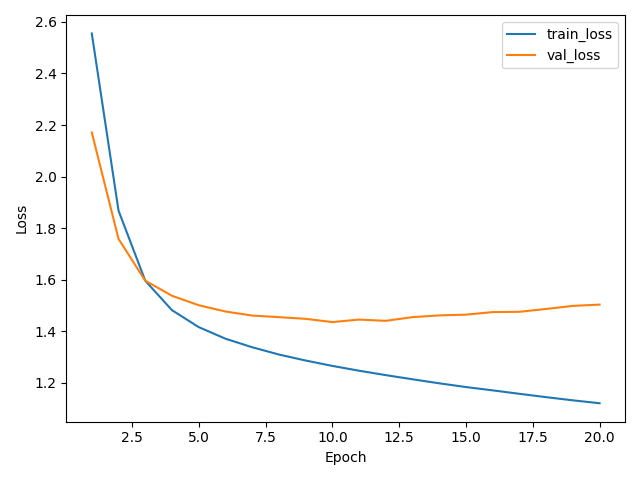

Selected epoch: 10


In [5]:
display(Image(filename=str(RUN / 'learning.png')))
if 'val_loss' in report['history'][0]:
    best_epoch = 1 + int(np.argmin([row['val_loss'] for row in report['history']]))
    print('Selected epoch:',best_epoch)

## Evaluation

Validation loss eventually rises while training loss continues falling, so the best validation checkpoint is restored. The sampled passage shows learned character and dialogue structure but contains grammatical errors and invented words. This is a small character model, not a general-purpose language model.

In [6]:
metrics = {name:value for name,value in report.items()
           if name in ('test_loss','test_accuracy','majority_baseline_accuracy',
                       'persistence_baseline_mse','perplexity','test_auc','test_brier')}
if metrics:
    display(pd.DataFrame(list(metrics.items()),columns=['Metric','Value']))
print('Timed training loop (including validation/checkpoint work):',round(report['training_seconds'],2),'seconds')

,Metric,Value
0,test_loss,1.787328
1,perplexity,5.973470


Timed training loop (including validation/checkpoint work): 49.61 seconds


In [7]:
print((RUN / 'generation.txt').read_text())

First Citizen:
Then, I must be not be so; if you had been reason
Do at one this last before thou shalt the mind
deservice of your gorder parties
His treasure I will to the bear that is young women to
His hand, the wind of place in himself,
So monthy this stood I will dire the battle fierce
And harbbler: therefore holjesty and Rome;
But if all half lone
The whop then of ceremony words, and Angelo
As a man's head 


## Artifacts and further work

`report.json` records the configuration and measured outcomes. `data.json` records split/preprocessing information; `best.npz` (supervised tasks) and `last.npz` contain model/training state. Figures and predictions are saved separately. Use the checkpoint tutorial to restore an existing architecture.

Change one factor at a time, retain validation-based selection, and avoid choosing configurations or samples to improve the apparent test result.